In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the pre-cleaned dataset
df = pd.read_csv('../data/processed/aha_cleaned.csv')
print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns.")

Loaded 1300 rows and 21 columns.


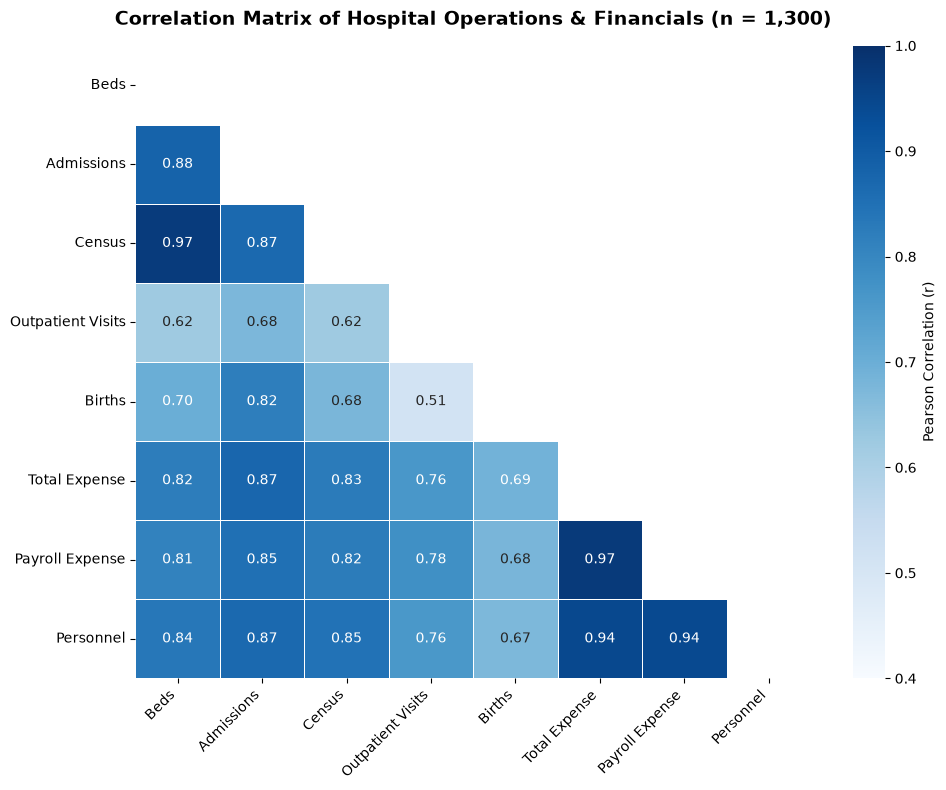

In [8]:
# 1. Select only the 8 true continuous operational & financial variables
num_cols = [
    'Beds', 'Admissions', 'Census', 'Outpatient Visits', 
    'Births', 'Total Expense', 'Payroll Expense', 'Personnel'
]

# 2. Compute correlation matrix and save as a clean CSV table
corr_matrix = df[num_cols].corr()
corr_matrix.round(3).to_csv('../outputs/tables/correlation_matrix.csv')

# 3. Mask the upper triangle to avoid visual clutter
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 4. Plot a publication-ready heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    vmin=0.4, vmax=1.0,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)

plt.title('Correlation Matrix of Hospital Operations & Financials (n = 1,300)', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Save high-res image for the PowerPoint
plt.savefig('../outputs/figures/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

Silhouette Score (k=3): 0.633

Cluster Summary Table:
                             Hospital Count   Beds  Admissions  Personnel  \
Hospital Tier                                                               
Tier 1: Small / Community               958  100.8      3165.9      489.3   
Tier 2: Mid-Size / Regional             300  420.1     18588.5     2593.6   
Tier 3: Large / Major Hubs               42  911.0     45412.2     8979.2   

                             Total Expense  
Hospital Tier                               
Tier 1: Small / Community          73708.1  
Tier 2: Mid-Size / Regional       451464.3  
Tier 3: Large / Major Hubs       1540525.9  


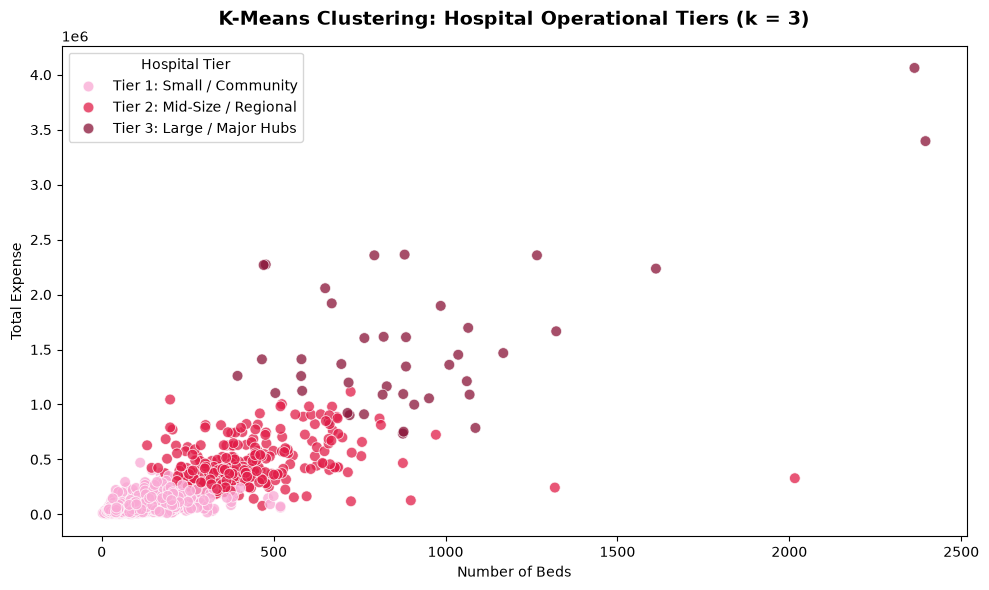

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Select core operational & financial scale metrics
cluster_cols = ['Beds', 'Admissions', 'Personnel', 'Total Expense']
X = df[cluster_cols]

# 2. Standardize features (crucial so large dollar amounts don't dominate Beds)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Fit K-Means with k=3 tiers
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Check clustering quality
sil_score = silhouette_score(X_scaled, df['Cluster'])
print(f"Silhouette Score (k=3): {sil_score:.3f}")

# 4. Sort clusters from smallest to largest by average Beds and assign clear labels
order = df.groupby('Cluster')['Beds'].mean().sort_values().index
cluster_map = {old: new for new, old in enumerate(order)}
df['Cluster'] = df['Cluster'].map(cluster_map)

tier_names = {
    0: 'Tier 1: Small / Community',
    1: 'Tier 2: Mid-Size / Regional',
    2: 'Tier 3: Large / Major Hubs'
}
df['Hospital Tier'] = df['Cluster'].map(tier_names)

# 5. Build and save the summary table
cluster_summary = df.groupby('Hospital Tier')[cluster_cols].mean().round(1)
cluster_summary.insert(0, 'Hospital Count', df['Hospital Tier'].value_counts())
cluster_summary.to_csv('../outputs/tables/cluster_summary.csv')
print("\nCluster Summary Table:")
print(cluster_summary)

# 6. Visualize the 3 tiers (Beds vs. Total Expense)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Beds',
    y='Total Expense',
    hue='Hospital Tier',
    palette=['#f9a9d4', '#e11d48', '#881337'],
    alpha=0.75,
    s=60
)

plt.title('K-Means Clustering: Hospital Operational Tiers (k = 3)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Beds')
plt.ylabel('Total Expense')
plt.legend(title='Hospital Tier')
plt.tight_layout()

plt.savefig('../outputs/figures/hospital_clusters.png', dpi=300, bbox_inches='tight')
plt.show()